# Module 02: Where it rains, seen from space

*The code behind GEOS 212: Water in the West, Boise State University*

In Module 02 we followed energy through the Earth system. Sunlight heats the tropics more than the poles, warm moist air rises near the equator, and the rising air drops its water as heavy rain. The air then sinks around 30° latitude, where the world's great deserts sit.

That's a story about *energy*, but it's written in *water*. In this notebook we'll look at 20 years of satellite precipitation measurements to see the pattern for ourselves, and then connect global rainfall back to Earth's energy budget with one line of arithmetic.

**Where are we in the water year?** Before it starts: in the *atmosphere*, where the energy that drives the whole water cycle comes from.

> **New to Jupyter?** Click a gray code cell and press **Shift + Enter** to run it. Run the cells in order.

## 1. Setup

In [1]:
import io, calendar
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import requests

try:
    import cartopy.crs as ccrs, cartopy.feature as cfeature
except ImportError:   # Google Colab doesn't include cartopy (map-drawing library); install it once
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cartopy"], check=True)
    import cartopy.crs as ccrs, cartopy.feature as cfeature

INK, DEEP, RIVER, GLACIER, OCHRE, BASALT, MIST = (
    "#14303F", "#0E4D64", "#137C8B", "#4FB0C6", "#D9822B", "#5B6770", "#EAF4F4")
plt.rcParams.update({"figure.dpi": 110, "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA_DIR = Path("../data")
DATA_URL = "https://raw.githubusercontent.com/LejoFlores/geos212-code/main/data/"

def load_saved(name):
    """Load a saved NumPy data file (.npz) from this repository's data/ folder,
    or download it from GitHub if you're running in Colab."""
    local = DATA_DIR / name
    if local.exists():
        return np.load(local)
    r = requests.get(DATA_URL + name, timeout=120)
    r.raise_for_status()
    return np.load(io.BytesIO(r.content))

## About the data: NASA GPM IMERG

The **Global Precipitation Measurement (GPM)** mission is a joint NASA and Japan (JAXA) satellite mission launched in 2014. A "core" satellite carries a precipitation radar and a microwave imager, and it calibrates a constellation of about ten partner satellites. **IMERG** (Integrated Multi-satellitE Retrievals for GPM) merges all of them, plus rain-gauge data, into one map of precipitation every half hour on a 0.1° grid (about 10 km), back to June 2000.

Downloading IMERG requires a free NASA Earthdata account, so to keep this notebook simple we load a copy of the data that we already downloaded and summarized. The last section shows the code that downloads it, if you want to try with your own account.

## 2. Loading 20 years of global precipitation

Our saved file holds the **mean annual precipitation** (mm per year) for water years 2006-2025, on a 0.5° grid (every 5th IMERG grid cell). It's stored as a NumPy `.npz` file: a bundle of named arrays.

In [2]:
g = load_saved("gpm_global_annual_wy2006_2025.npz")
lat, lon, P = g["lat"], g["lon"], g["p_mm_per_yr"]
print("arrays in the file:", list(g.keys()))
print("grid shape (lat, lon):", P.shape)
print(f"latitudes {lat.min():.2f} to {lat.max():.2f}, longitudes {lon.min():.2f} to {lon.max():.2f}")

arrays in the file: ['lat', 'lon', 'p_mm_per_yr']
grid shape (lat, lon): (360, 720)
latitudes -89.75 to 89.75, longitudes -179.75 to 179.75


## 3. A map of where it rains

We'll draw the map with **cartopy**, a Python library for maps. `pcolormesh` colors each grid cell by its value. IMERG covers the whole globe, but it is most reliable between 60° S and 60° N (snow and ice at high latitudes confuse the satellite sensors), so that's the part we show on the map.

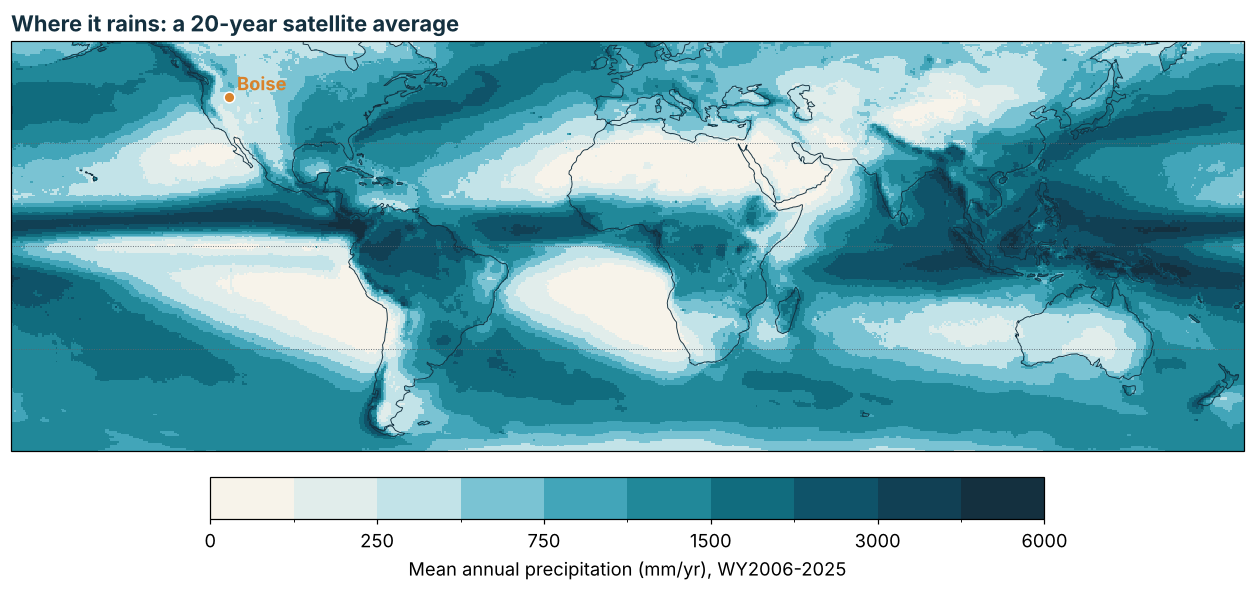

In [3]:
water_cmap = mcolors.LinearSegmentedColormap.from_list("water", ["#F7F3EA", "#CFE8EC", GLACIER, RIVER, DEEP, INK])
levels = [0, 100, 250, 500, 750, 1000, 1500, 2000, 3000, 4000, 6000]

fig = plt.figure(figsize=(13, 5.5))
ax = plt.axes(projection=ccrs.PlateCarree())
im = ax.pcolormesh(lon, lat, P, cmap=water_cmap, norm=mcolors.BoundaryNorm(levels, water_cmap.N),
                   transform=ccrs.PlateCarree())
ax.coastlines(lw=0.6, color=INK)
ax.set_extent([-180, 180, -60, 60], ccrs.PlateCarree())
for y in (-30, 0, 30):
    ax.axhline(y, color=BASALT, lw=0.6, ls=":")
ax.plot(-116.2, 43.6, "o", ms=7, mfc=OCHRE, mec="white", transform=ccrs.PlateCarree())
ax.text(-114, 45.5, "Boise", color=OCHRE, fontweight="bold", transform=ccrs.PlateCarree())
plt.colorbar(im, orientation="horizontal", shrink=0.6, pad=0.05, label="Mean annual precipitation (mm/yr), WY2006-2025")
ax.set_title("Where it rains: a 20-year satellite average", loc="left", fontweight="bold", color=INK)
plt.tight_layout()

**Things to find on the map:**
* A band of heavy rain hugging the equator: the **Intertropical Convergence Zone (ITCZ)**. Notice it sits a bit north of the equator over the Pacific and Atlantic.
* Dry belts near 30° N and 30° S: the Sahara, Arabian, Australian, Kalahari and Atacama deserts.
* Wet mid-latitude storm tracks over the North Pacific and North Atlantic, and the Southern Ocean.
* Mountains squeezing out precipitation: the Andes, the Himalaya, the Pacific Northwest coast (that's Module 03, orographic lifting!).

## 4. Averaging around the globe: the zonal mean

A **zonal mean** averages along each line of latitude (across all longitudes). It boils the map down to one curve that shows how precipitation changes from pole to pole.

Wettest latitude band: 2,508 mm/yr at 6.2°


/tmp/ipykernel_388/3426490986.py:1: RuntimeWarning: Mean of empty slice
  zonal = np.nanmean(P, axis=1)        # average across longitudes (axis 1) for each latitude


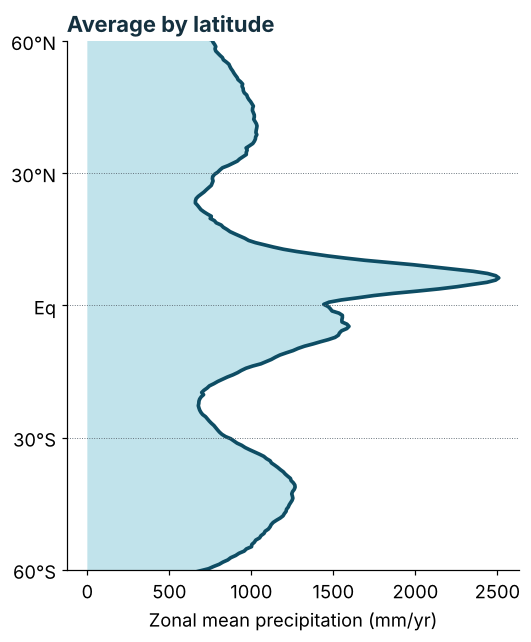

In [4]:
zonal = np.nanmean(P, axis=1)        # average across longitudes (axis 1) for each latitude

fig, ax = plt.subplots(figsize=(5, 6))
ax.fill_betweenx(lat, 0, zonal, color=GLACIER, alpha=0.35, lw=0)
ax.plot(zonal, lat, color=DEEP, lw=2.4)
for y in (-30, 0, 30):
    ax.axhline(y, color=BASALT, lw=0.6, ls=":")
ax.set_ylim(-60, 60); ax.set_yticks([-60, -30, 0, 30, 60], ["60°S", "30°S", "Eq", "30°N", "60°N"])
ax.set_xlabel("Zonal mean precipitation (mm/yr)")
ax.set_title("Average by latitude", loc="left", fontweight="bold", color=INK)
plt.tight_layout()

i = np.nanargmax(zonal)          # nanargmax skips missing (NaN) values
print(f"Wettest latitude band: {zonal[i]:,.0f} mm/yr at {lat[i]:.1f}°")

## 5. One global number, and the energy budget

What's the average precipitation over the whole planet? We can't just average all the grid cells: a 0.5° cell near the equator covers far more area than one near 60°, because lines of longitude converge toward the poles. The area of a cell is proportional to the **cosine of its latitude**, so we use that as a weight.

In [5]:
ok = np.isfinite(zonal)                      # skip any latitude rows with no data
weights = np.cos(np.deg2rad(lat[ok]))
global_mean = np.sum(zonal[ok] * weights) / np.sum(weights)
print(f"Area-weighted global mean:  {global_mean:,.0f} mm/yr")
print(f"Unweighted (wrong!) mean:   {np.mean(zonal[ok]):,.0f} mm/yr   <- gives the dry poles far too much say")

Area-weighted global mean:  1,011 mm/yr
Unweighted (wrong!) mean:   810 mm/yr   <- gives the dry poles far too much say


Now the payoff. Every millimeter of rain had to be evaporated first, and evaporating water takes energy: the **latent heat of vaporization**, $L_v \approx 2.45 \times 10^6$ J per kg. In the IPCC's global energy budget (AR6, Figure 7.2), the surface loses about **82 W m⁻²** to evaporation (latent heat flux).

How much precipitation does that imply? Since 1 kg of water spread over 1 m² is 1 mm deep:

$$P = \frac{82\ \text{J s}^{-1}\text{m}^{-2}}{2.45\times10^{6}\ \text{J kg}^{-1}} \times 3.156\times10^{7}\ \tfrac{\text{s}}{\text{yr}} \approx 1{,}060\ \tfrac{\text{kg}}{\text{m}^2\,\text{yr}} = 1{,}060\ \text{mm/yr}$$

In [6]:
LATENT_HEAT_FLUX = 82          # W/m^2, IPCC AR6 Figure 7.2
Lv = 2.45e6                    # J/kg
SECONDS_PER_YEAR = 365.25 * 24 * 3600
P_from_energy = LATENT_HEAT_FLUX / Lv * SECONDS_PER_YEAR
print(f"Precipitation implied by the energy budget: {P_from_energy:,.0f} mm/yr")
print(f"Measured by satellites (whole globe):        {global_mean:,.0f} mm/yr")

Precipitation implied by the energy budget: 1,056 mm/yr
Measured by satellites (whole globe):        1,011 mm/yr


Two completely different approaches, one from an energy budget and one from satellites, agree to within about 5%. The water cycle and the energy cycle are the same cycle. (Satellites have trouble seeing light rain and snow, especially over snow-covered and icy high latitudes, and both numbers have uncertainties of several percent, so we shouldn't expect a perfect match.)

## 6. Your turn

1. **Boise's latitude.** Look up the zonal mean at 43.6° N (`zonal[np.argmin(abs(lat - 43.6))]`). Boise gets about 300 mm/yr. Is Boise wetter or drier than the average for its latitude? Why? (Think rain shadows: Module 03.)
2. **Hemispheres.** Compute the area-weighted mean separately for the Northern and Southern Hemispheres. Which hemisphere is wetter? Why might that be? (Hint: where is the ITCZ?)
3. **Land vs. ocean.** Use `cartopy.feature.LAND` or the `regionmask` package to separate land and ocean cells. What fraction of precipitation falls on the ocean?

### Why code?
Twenty years of half-hourly satellite measurements is billions of numbers. Code turns them into one map, one curve, and one number in a few lines, and lets you check that number against an entirely independent physical estimate.

## Optional: download the data yourself

Want to get IMERG directly from NASA? Make a free account at [urs.earthdata.nasa.gov](https://urs.earthdata.nasa.gov/), generate a *token* (under "Generate Token"), and paste it below. The cell asks NASA's GES DISC data server for one month of precipitation over the western US, using a web address that requests just the slice of the global grid we want (this is called **OPeNDAP** subsetting, and it saves downloading the whole globe).

It's set to `RUN_DOWNLOAD = False` so the notebook works without an account.

In [7]:
RUN_DOWNLOAD = False
EARTHDATA_TOKEN = "paste-your-token-here"

if RUN_DOWNLOAD:
    import xarray as xr   # reads the netCDF file NASA sends back
    year, month = 2023, 1
    url = ("https://gpm1.gesdisc.eosdis.nasa.gov/opendap/GPM_L3/GPM_3IMERGM.07/"
           f"{year}/3B-MO.MS.MRG.3IMERG.{year}{month:02d}01-S000000-E235959.{month:02d}.V07B.HDF5.dap.nc4"
           # grid indices: lon = -179.95 + 0.1*i, lat = -89.95 + 0.1*j  (western US box)
           "?dap4.ce=/precipitation[0][550:759][1210:1394];/lat[1210:1394];/lon[550:759]")
    r = requests.get(url, headers={"Authorization": f"Bearer {EARTHDATA_TOKEN}"}, timeout=180)
    r.raise_for_status()
    ds = xr.open_dataset(io.BytesIO(r.content))
    rate = ds.precipitation.values[0].T                     # mm per hour, shape (lat, lon)
    total = rate * 24 * calendar.monthrange(year, month)[1]  # mm for the month
    plt.pcolormesh(ds.lon, ds.lat, total, cmap="Blues"); plt.colorbar(label="mm")
    plt.title(f"IMERG precipitation, {year}-{month:02d}")

---
*Data: NASA GPM IMERG V07 Final Run monthly (GPM_3IMERGM.07, doi:10.5067/GPM/IMERG/3B-MONTH/07), NASA GES DISC. Energy budget: IPCC AR6 WG1 Chapter 7, Figure 7.2.*